# Learning curves for GaussianNB: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/model_selection/plot_learning_curve.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/model_selection/plot_learning_curve.html)).

**Scenario:** the bundled digits dataset (1 797 images, 64 features, 10 classes); `GaussianNB` is evaluated with
`learning_curve` / `LearningCurveDisplay` over `train_sizes=np.linspace(0.1, 1.0, 5)` and
`ShuffleSplit(n_splits=50, test_size=0.2, random_state=0)`, reporting training and test accuracy.

**Adaptations:**
- The 50 `ShuffleSplit` folds are generated by scikit-learn and shared with Mojo as index arrays, so both sides
  score identical folds (Moxie's own seeded shuffles use a different RNG stream; that is model_selection's
  documented adaptation, see #3). Fractional `train_sizes` are passed as the absolute sizes scikit-learn derives
  from them (`[143, 467, 790, 1113, 1437]`).
- `moxie.model_selection.learning_curve` takes an explicit `CVAdapter` (row slicing, fit) and a `TypedScorer`
  (model_selection's documented typed API); the Mojo cell defines both for `GaussianNB`, following
  `families/model_selection/algorithms/validation/tests/incremental_gaussian.mojo`. Labels use the
  `GaussianNB[NumericDomain[DType.int64]]` domain.
- Besides the example's ordinary refits, the notebook also runs `exploit_incremental_learning=True`, which drives
  `GaussianNB.partial_fit(..., classes=...)` and is compared against the same reference option.
- The SVC half of the example and the fit/score timing plots are not reproduced (svm family; timings are not a
  parity quantity). `n_jobs=4` is kept for the reference display only.
- `make_pipeline(StandardScaler(), GaussianNB())` is attempted in an expect-fail cell (composition check).

**Determinism:** deterministic: fixed `random_state=0` folds and closed-form `GaussianNB` fits.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("naive_bayes/plot_learning_curve")

## 1. scikit-learn (Python reference)

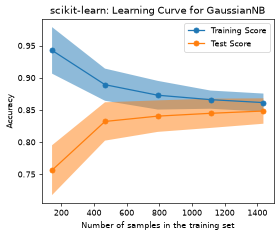

train_sizes: [ 143  467  790 1113 1437]
mean test accuracy: [0.7563 0.8321 0.8404 0.8448 0.8483]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import LearningCurveDisplay, ShuffleSplit, learning_curve
from sklearn.naive_bayes import GaussianNB

X, y = load_digits(return_X_y=True)
naive_bayes = GaussianNB()

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), dpi=60)
common_params = {
    "X": X,
    "y": y,
    "train_sizes": np.linspace(0.1, 1.0, 5),
    "cv": ShuffleSplit(n_splits=50, test_size=0.2, random_state=0),
    "score_type": "both",
    "n_jobs": 4,
    "line_kw": {"marker": "o"},
    "std_display_style": "fill_between",
    "score_name": "Accuracy",
}
LearningCurveDisplay.from_estimator(naive_bayes, **common_params, ax=ax)
handles, label = ax.get_legend_handles_labels()
ax.legend(handles[:2], ["Training Score", "Test Score"])
ax.set_title(f"scikit-learn: Learning Curve for {naive_bayes.__class__.__name__}")
plt.show()

cv = ShuffleSplit(n_splits=50, test_size=0.2, random_state=0)
splits = list(cv.split(X, y))
sk = {}
for incremental in (False, True):
    sizes, train_scores, test_scores = learning_curve(
        naive_bayes, X, y, train_sizes=np.linspace(0.1, 1.0, 5), cv=splits,
        exploit_incremental_learning=incremental)
    sk[incremental] = (sizes, train_scores, test_scores)
print("train_sizes:", sk[False][0])
print("mean test accuracy:", np.round(sk[False][2].mean(axis=1), 4))
nb.share(X=X.astype(np.float64), y=y.astype(np.int64),
         train_idx=np.stack([tr for tr, _ in splits]).astype(np.int64),
         test_idx=np.stack([te for _, te in splits]).astype(np.int64),
         sizes=sk[False][0].astype(np.int64))

## 2. Moxie (native Mojo)

`learning_curve` with the shared folds, ordinary refits and `exploit_incremental_learning=True`.

In [3]:
%%mojo learning_curve
from numojo import NDArray, Shape, Item
from moxie.naive_bayes import GaussianNB, NumericDomain
from moxie.model_selection import TypedScorer, IndexArray, IndexSplit, IncrementalCVAdapter, learning_curve
from moxie.model_selection._split import _rows
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]
comptime Model = GaussianNB[NumericDomain[DType.int64]]


struct Accuracy(TypedScorer):
    comptime Estimator = Model
    comptime Input = Dense
    comptime Target = IndexArray
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def score(self, estimator: Model, X: Dense, y: IndexArray, metadata: NoneType) raises -> Float64:
        return estimator.score(X, y)


struct GaussianAdapter(IncrementalCVAdapter):
    comptime Scorer = Accuracy

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: IndexArray) raises -> Int:
        return y.size

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: IndexArray, rows: IndexArray) raises -> IndexArray:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) -> NoneType:
        return None

    def fit(self, mut estimator: Model, X: Dense, y: IndexArray, metadata: NoneType) raises:
        _ = estimator.fit(X, y)

    def partial_fit(self, mut estimator: Model, X: Dense, y: IndexArray, metadata: NoneType,
                    full_target: IndexArray) raises:
        _ = estimator.partial_fit(X, y, classes=full_target.copy())


def row(table: NDArray[DType.int64], r: Int) raises -> IndexArray:
    var out = IndexArray(Shape(table.shape[1]))
    for i in range(table.shape[1]):
        out[Item(i)] = table.item(r, i)
    return out^


def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var train_idx = load[DType.int64]("train_idx")
    var test_idx = load[DType.int64]("test_idx")
    var sizes = load[DType.int64]("sizes")
    var cv = List[IndexSplit]()
    for s in range(train_idx.shape[0]):
        cv.append(IndexSplit(row(train_idx, s), row(test_idx, s)))
    var model = Model()
    for incremental in [False, True]:
        var result = learning_curve[GaussianAdapter, DType.int64](
            model, X, y, GaussianAdapter(), Accuracy(), cv, None, None,
            train_sizes=sizes.copy(), exploit_incremental_learning=incremental)
        var tag = String("incremental") if incremental else String("refit")
        save(tag + "_sizes", result.train_sizes)
        save(tag + "_train", result.train_scores)
        save(tag + "_test", result.test_scores)
    # learning_curve clones the estimator; the template stays unfitted.
    print("template fitted after learning_curve:", model.__sklearn_is_fitted__())

template fitted after learning_curve: False


### Composition check: GaussianNB after an NDArray transformer in a Pipeline

`make_pipeline(StandardScaler(), GaussianNB())` is a one-liner in scikit-learn. In Moxie, `GaussianNB`'s trait
`Input` is `List[List[Float64]]` (its NDArray overloads are extra methods), so the Pipeline rejects it at compile time
(the `rebind` of the scaler's `NDArray` output to `GaussianNB.Input` in `_pipeline_sequential.mojo` fails).

In [4]:
%%mojo pipeline_scaler_gaussian_nb --expect-fail
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie.naive_bayes import GaussianNB
from moxie_nb_io import load, load_ints


def main() raises:
    var X = load("X")
    var y = load_ints("y")
    var pipe = make_pipeline(StandardScaler(), GaussianNB())
    _ = pipe.fit(X, y)
    print(pipe.score(X, y))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/naive_bayes/plot_learning_curve/pipeline_scaler_gaussian_nb.mojo:7:5: error: function instantiation failed
def main() raises:
    ^
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/naive_bayes/plot_learning_curve/pipeline_scaler_gaussian_nb.mojo:12:21: note: call expansion failed with parameter value(s): (..., ...)
    print(pipe.score(X, y))
                    ^
Included from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/naive_bayes/plot_learning_curve/pipeline_scaler_gaussian_nb.mojo:1:
Included from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
Included from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_pipeline_api.mojo:6:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_p

## 3. Side by side and parity

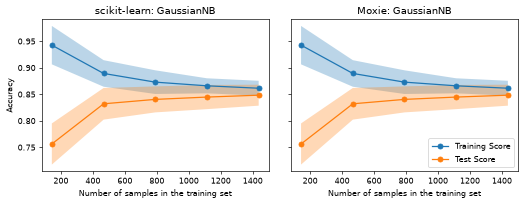

In [5]:
mx = nb.results["learning_curve"]
moxie_nb.side_by_side(
    sklearn={"train size": sk[False][0], "train acc": np.round(sk[False][1].mean(axis=1), 4),
             "test acc": np.round(sk[False][2].mean(axis=1), 4)},
    moxie={"train size": mx["refit_sizes"], "train acc": np.round(mx["refit_train"].mean(axis=1), 4),
           "test acc": np.round(mx["refit_test"].mean(axis=1), 4)})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), dpi=60, sharey=True)
for ax, (title, sizes, tr, te) in zip(axes, [("scikit-learn", *sk[False]),
                                              ("Moxie", mx["refit_sizes"], mx["refit_train"], mx["refit_test"])]):
    for scores, name in ((tr, "Training Score"), (te, "Test Score")):
        m, s = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(sizes, m, "o-", label=name)
        ax.fill_between(sizes, m - s, m + s, alpha=0.3)
    ax.set(title=f"{title}: GaussianNB", xlabel="Number of samples in the training set")
axes[0].set_ylabel("Accuracy"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

In [6]:
for incremental, tag in ((False, "refit"), (True, "incremental")):
    sizes, train_scores, test_scores = sk[incremental]
    nb.compare(f"{tag}: train_sizes_abs", sizes, mx[f"{tag}_sizes"], exact=True)
    nb.compare(f"{tag}: train_scores (5 sizes x 50 folds)", train_scores, mx[f"{tag}_train"], exact=True)
    nb.compare(f"{tag}: test_scores (5 sizes x 50 folds)", test_scores, mx[f"{tag}_test"], exact=True)
nb.note("make_pipeline(StandardScaler(), GaussianNB())", "GAP",
        "compile-time rejection: GaussianNB.Input is List[List[Float64]], not the scaler's NDArray output "
        "(rebind failure in _pipeline_sequential.mojo). Owner: naive_bayes; listed as part 5 of the pipeline verification report.")
nb.note("CV folds / train_sizes", "ADAPTED", "ShuffleSplit folds and absolute sizes shared from scikit-learn; "
        "learning_curve takes an explicit CVAdapter and TypedScorer (model_selection typed API).")
nb.note("SVC half and timing plots", "GAP", "not reproduced here (svm family; timings are not compared).")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
refit: train_sizes_abs,PASS,"(5,)","(5,)",,,exact,0 mismatches,
refit: train_scores (5 sizes x 50 folds),PASS,"(5, 50)","(5, 50)",,,exact,0 mismatches,
refit: test_scores (5 sizes x 50 folds),PASS,"(5, 50)","(5, 50)",,,exact,0 mismatches,
incremental: train_sizes_abs,PASS,"(5,)","(5,)",,,exact,0 mismatches,
incremental: train_scores (5 sizes x 50 folds),PASS,"(5, 50)","(5, 50)",,,exact,0 mismatches,
incremental: test_scores (5 sizes x 50 folds),PASS,"(5, 50)","(5, 50)",,,exact,0 mismatches,
"make_pipeline(StandardScaler(), GaussianNB())",GAP,,,,,,"compile-time rejection: GaussianNB.Input is List[List[Float64]], not the scaler's NDArray output (rebind failure in _pipeline_sequential.mojo). Owner: naive_bayes; listed as part 5 of the pipeline verification report.",
CV folds / train_sizes,ADAPTED,,,,,,ShuffleSplit folds and absolute sizes shared from scikit-learn; learning_curve takes an explicit CVAdapter and TypedScorer (model_selection typed API).,
SVC half and timing plots,GAP,,,,,,not reproduced here (svm family; timings are not compared).,
